# 🔍 [AI 트랙] XAI 과제 — 내 모델은 어디를 보고 있을까?

<div style="background:#EFF4FF;border-left:6px solid #1E3A8A;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#1E3A8A">🎯 과제 목적</b><br>수업에서 배운 XAI 기법(Grad-CAM · LIME · SHAP)을 <b>직접 구현하고 적용</b>해 봅니다. 핵심은 코드를 완성하는 것이 아니라, <b>두 기법이 같은 이미지에 대해 내놓는 설명을 비교하고, 왜 그런 차이가 나는지 수업 내용(분류 축: Gradient vs Perturbation)으로 해석하는 것</b>입니다. 각자 학번 기반 시드로 <b>서로 다른 이미지</b>가 배정되므로, 남의 답을 복사하면 해석이 어긋납니다. 마지막에는 '설명 자체를 의심하는' sanity check까지 경험합니다.</div>


<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">✍️ 기술 블로그 연결 (꼭 읽어주세요!)</b><br>이 과제의 결과물은 여러분의 <b>논문 리뷰 기술 블로그</b>와 연결됩니다.<br><b>문제 1.3(Grad-CAM 클래스별 히트맵), 1.4~1.5(LIME 실험과 Grad-CAM 비교), 심화 2.2(sanity check)</b>의 결과 그래프와 여러분의 해석을 블로그에 옮겨 작성해 주세요. LIME 논문(Why Should I Trust You?) 리뷰에 '내가 직접 돌려본 LIME' 섹션이 들어가면 훨씬 좋은 글이 됩니다.</div>


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">🤖 생성형 AI 사용 규칙</b><br>GPT/Claude 사용 <b>허용</b>합니다. 단 ① 에러 해결·문법 질문에 쓰는 것은 자유, ② <b>해석·비교·결론은 반드시 본인의 문장</b>으로 쓸 것 (실험 결과는 각자 다르므로 AI가 대신 써줄 수 없습니다), ③ <b>마지막 '3. 생성형 AI 활용 기록' 셀에 사용 내역과 대화 내용을 꼭 남길 것.</b> 기록 없이 AI 문체만 남은 답안은 감점됩니다.</div>

---
**제출물**: 이 노트북 완성본(.ipynb) 1개 — 모든 셀 실행 결과가 남아 있는 상태로 제출


## 📋 목차

| 번호 | 내용 | 난이도 |
|---|---|---|
| **0** | 환경 설정 — 라이브러리 · 내 시드 · 이미지 배정 | 🟢 |
| **1.1** | 사전학습 CNN 준비, 배정 이미지 예측 확인 | 🟢 |
| **1.2** | **Grad-CAM 직접 구현** (hook + α 계산 + ReLU) | 🔴 핵심 |
| **1.3** | 클래스별 히트맵 비교 실험과 해석 | 🟡 |
| **1.4** | LIME 적용 — 하이퍼파라미터 · 불안정성 실험 | 🟡 |
| **1.5** | Grad-CAM vs LIME 종합 비교 (서술) | 🟡 |
| **2.1** | (심화) SHAP — 표 데이터에서 Local↔Global | 🟡 선택 |
| **2.2** | (심화) Sanity Check — 설명을 의심하기 | 🔴 선택 |
| **3** | 생성형 AI 활용 기록 (**필수 제출**) | — |
| **4** | 회고 | — |


# 0. 환경 설정

<div style="background:#EFF4FF;border-left:6px solid #1E3A8A;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#1E3A8A">💡 시작 전에</b><br>런타임 유형을 <b>GPU</b>로 바꿔주세요 (상단 메뉴: 런타임 → 런타임 유형 변경 → T4 GPU). CPU로도 돌아가지만 LIME 실험(1.4)이 오래 걸립니다.<br>아래 설치·다운로드 셀은 처음 한 번만 실행하면 됩니다 (1~2분 소요).</div>

In [1]:
# 라이브러리 설치 (Colab 기본 환경에 없는 것만)
!pip -q install lime shap

# 실습용 이미지: ImageNet 1000개 클래스에서 클래스당 1장씩 모아둔 공개 저장소
!if [ ! -d imagenet-sample-images ]; then git clone -q --depth 1 https://github.com/EliSchwartz/imagenet-sample-images.git; fi
!ls imagenet-sample-images | head -3


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
gallery.md
n01440764_tench.JPEG
n01443537_goldfish.JPEG


In [2]:
import os, random, copy
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
import matplotlib.pyplot as plt
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)   # 'cuda'가 아니면 런타임 유형을 확인하세요


사용 장치: cuda


In [3]:
# ──────────────────────────────────────────────
#  내 실험 조건 만들기 : 학번이 곧 나의 시드!
#  (같은 시드 = 같은 이미지 배정. 답안이 서로 다른 이유입니다)
# ──────────────────────────────────────────────
STUDENT_ID = 20231009   # TODO: 본인 학번을 숫자로 입력하세요 (예: 2271234)

assert STUDENT_ID != 0, "본인 학번을 입력해 주세요!"
SEED = STUDENT_ID % 10000
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"나의 실험 시드: {SEED}")


나의 실험 시드: 1009


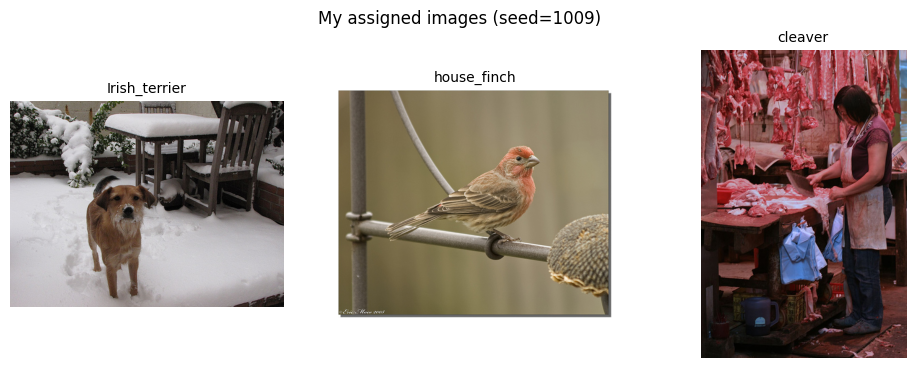

In [4]:
# 시드로 나만의 이미지 3장 배정받기
IMG_DIR = "imagenet-sample-images"
all_files = sorted(f for f in os.listdir(IMG_DIR) if f.upper().endswith(".JPEG"))
my_files = random.Random(SEED).sample(all_files, 3)

my_images = [Image.open(os.path.join(IMG_DIR, f)).convert("RGB") for f in my_files]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, name in zip(axes, my_images, my_files):
    ax.imshow(img); ax.axis("off")
    ax.set_title(name.split("_", 1)[-1].replace(".JPEG", ""), fontsize=10)
# 그래프 안 텍스트는 영문 사용 — Colab 기본 폰트에 한글이 없어 □로 깨집니다
plt.suptitle(f"My assigned images (seed={SEED})")
plt.show()


# 1. 필수 과제

## 1.1 사전학습 CNN 준비 — 모델은 내 이미지를 뭐라고 볼까?

ImageNet으로 학습된 **ResNet-18**을 불러와서, 배정받은 이미지 3장에 대한 **top-5 예측**을 확인합니다.
이 예측 결과가 이후 모든 문제의 출발점이 됩니다. *(이 단계는 코드가 거의 완성되어 있어요 — 주석 빈칸만 채우면 됩니다)*

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💬 주석 빈칸이란?</b><br>코드 중간의 <code># (빈칸 A) ...</code> 주석을 채우는 문제입니다. '내가 지금 어느 단계의 무엇을 하고 있는지'를 스스로 설명할 수 있어야 나중에 코드를 응용할 수 있기 때문에 넣었습니다. 한 줄이면 충분합니다!</div>

In [5]:
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).to(device).eval()   # (빈칸 A) .eval()을 호출하는 이유는? → 모델을 평가 모드로 전환하여 Batch Normalization 등이 학습할 때와 다르게 동작하도록 하기 위해서이다.
categories = weights.meta["categories"]               # ImageNet 1000개 클래스 이름
preprocess = weights.transforms()                     # (빈칸 B) 이 전처리가 하는 일 두 가지는? → 입력 이미지를 ResNet18에 밎는 크기로 변환하고, ImageNet의 평균과 표준 편차를 이용해 정규화한다.

def predict_probs(img_pil):
    """PIL 이미지 → 1000개 클래스 확률 (torch.Tensor, shape [1000])"""
    x = preprocess(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():                             # (빈칸 C) 여기서 no_grad를 쓰는 이유는? → 학습이 아니라 추론 과정에서는 역전파가 필요하지 않기 때문에 gradient 계산을 비활성화해 메모리 사용량과 연산 부담을 줄인다.
        logits = model(x)
    return F.softmax(logits, dim=1)[0].cpu()

for name, img in zip(my_files, my_images):
    probs = predict_probs(img)
    top5 = probs.topk(5)
    print(f"\n📷 {name}")
    for p, idx in zip(top5.values, top5.indices):
        print(f"   {categories[idx]:30s} {p*100:5.1f}%")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]



📷 n02093991_Irish_terrier.JPEG
   golden retriever                23.3%
   Labrador retriever              20.5%
   Border terrier                  17.2%
   Irish terrier                    4.4%
   bloodhound                       2.7%

📷 n01532829_house_finch.JPEG
   house finch                     99.8%
   brambling                        0.1%
   goldfinch                        0.1%
   junco                            0.0%
   indigo bunting                   0.0%

📷 n03041632_cleaver.JPEG
   butcher shop                    99.7%
   cleaver                          0.2%
   grocery store                    0.0%
   handkerchief                     0.0%
   mosquito net                     0.0%


## 1.2 🔴 Grad-CAM 직접 구현 — 이 과제의 포인트

수업에서 배운 5단계 파이프라인을 그대로 코드로 옮깁니다. 라이브러리(`pytorch-grad-cam` 등)를 쓰지 않고
**hook으로 직접** 구현하는 것이 포인트입니다.

> **수업 복습** — ① Forward로 클래스 점수 $y^c$ 계산 → ② $y^c$를 마지막 conv의 feature map $A^k$까지 backward →
> ③ gradient를 공간 평균해 채널 가중치 $\alpha_k^c$ → ④ $\sum_k \alpha_k^c A^k$ 후 ReLU → ⑤ 입력 크기로 upsample

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💡 힌트</b><br>· hook은 '모델이 계산하는 중간 값을 몰래 저장하는 장치'입니다. forward hook은 활성값 A^k를, backward hook은 ∂y^c/∂A^k를 잡아둡니다 (둘 다 코드로 제공됨).<br>· <b>TODO 1</b>: gradient 텐서 shape은 [1, K, h, w]. 공간 축(h, w)에 대해 평균하면 α가 됩니다 → <code>mean(dim=?)</code><br>· <b>TODO 2</b>: α(shape [1,K,1,1])와 activations([1,K,h,w])를 곱해 채널 축으로 합한 뒤 ReLU → 수업의 2×2 손계산 예제와 같은 연산!<br>· 잘 됐는지 확인: 다음 셀의 시각화에서 히트맵이 물체 위에 얹혀야 정상입니다.</div>

In [10]:
class GradCAM:
    """수업의 5단계 파이프라인을 그대로 구현한 최소 Grad-CAM"""

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None   # A^k  가 저장될 자리
        self.gradients = None     # ∂y^c/∂A^k 가 저장될 자리
        # hook 등록: forward/backward 때 중간값을 가로채 저장
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()          # shape [1, K, h, w]

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()    # shape [1, K, h, w]

    def __call__(self, x, class_idx=None):
        # ① Forward — 클래스 점수 계산
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()

        # ② Backward — 선택한 클래스 점수만 미분
        score = logits[0, class_idx]
        score.backward()

        # ③ 채널 가중치 α_k^c 계산
        # (빈칸 D) 이 줄이 수업 슬라이드의 어떤 수식에 해당하는지 쓰세요 → GradeCam에서 채널 가중치를 계산하는 부분으로, 클래스 점수의 기울기를 평균해 가중치를 획득한다.
        alpha = self.gradients.mean(dim=(2, 3), keepdim=True)   # TODO 1: self.gradients 를 공간 축에 대해 평균 (keepdim=True 권장)

        # ④ 가중합 + ReLU
        # (빈칸 E) ReLU를 마지막에 적용하는 이유는? → 선택한 클래스의 예측에 긍정적으로 기여하는 영역만 강조하고, 부정적으로 기여하는 영역은 제거하기 위해서이다.
        cam = F.relu((alpha * self.activations).sum(dim=1))     # TODO 2: (alpha * self.activations)를 채널 축으로 합한 뒤 F.relu

        # ⑤ 정규화 + 입력 크기로 upsample (완성되어 있음)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = F.interpolate(cam.unsqueeze(0), size=x.shape[-2:],
                            mode="bilinear", align_corners=False)
        return cam[0, 0].cpu().numpy(), class_idx

# 마지막 conv 블록(layer4의 마지막 BasicBlock)에 hook을 겁니다
gradcam = GradCAM(model, model.layer4[-1])
print("GradCAM 준비 완료")


GradCAM 준비 완료


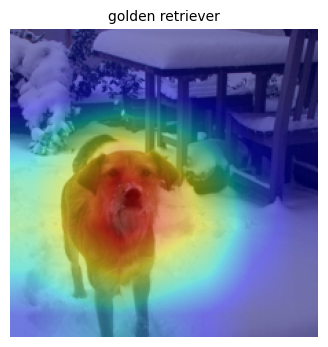

In [11]:
# 시각화 도우미 (완성 코드 — 그대로 실행)
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

def to_numpy_img(x):
    """정규화된 텐서[3,H,W] → 화면 표시용 numpy[H,W,3]"""
    return (x.cpu() * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

def show_gradcam(img_pil, class_idx=None, ax=None, title=None):
    x = preprocess(img_pil).unsqueeze(0).to(device)
    cam, used_idx = gradcam(x, class_idx)
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(to_numpy_img(x[0])); ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.axis("off"); ax.set_title(title or categories[used_idx], fontsize=10)
    return used_idx

# 동작 확인: 첫 번째 배정 이미지의 top-1 히트맵
show_gradcam(my_images[0])
plt.show()


## 1.3 실험 — 같은 이미지, 다른 클래스로 미분하면?

Grad-CAM의 매력은 **class-discriminative**, 즉 "어느 클래스 입장에서 보는가"를 우리가 고를 수 있다는 점이었죠
(수업의 Cat/Dog 그림). 내 이미지 3장 각각에 대해 **top-1 클래스 히트맵과 top-2 클래스 히트맵**을 나란히 그려 비교하세요.

**해야 할 일**
1. 아래 셀을 완성해 3장 × (원본 | top-1 CAM | top-2 CAM) 그리드를 그린다
2. 그림 아래 답안 셀에 해석을 쓴다 — *top-1과 top-2 히트맵이 다른 곳을 비추는 이미지가 있나요? 그 이유는 무엇일까요?
모델이 엉뚱한 곳(배경 등)을 보는 경우가 있다면 그것은 무엇을 시사하나요?*

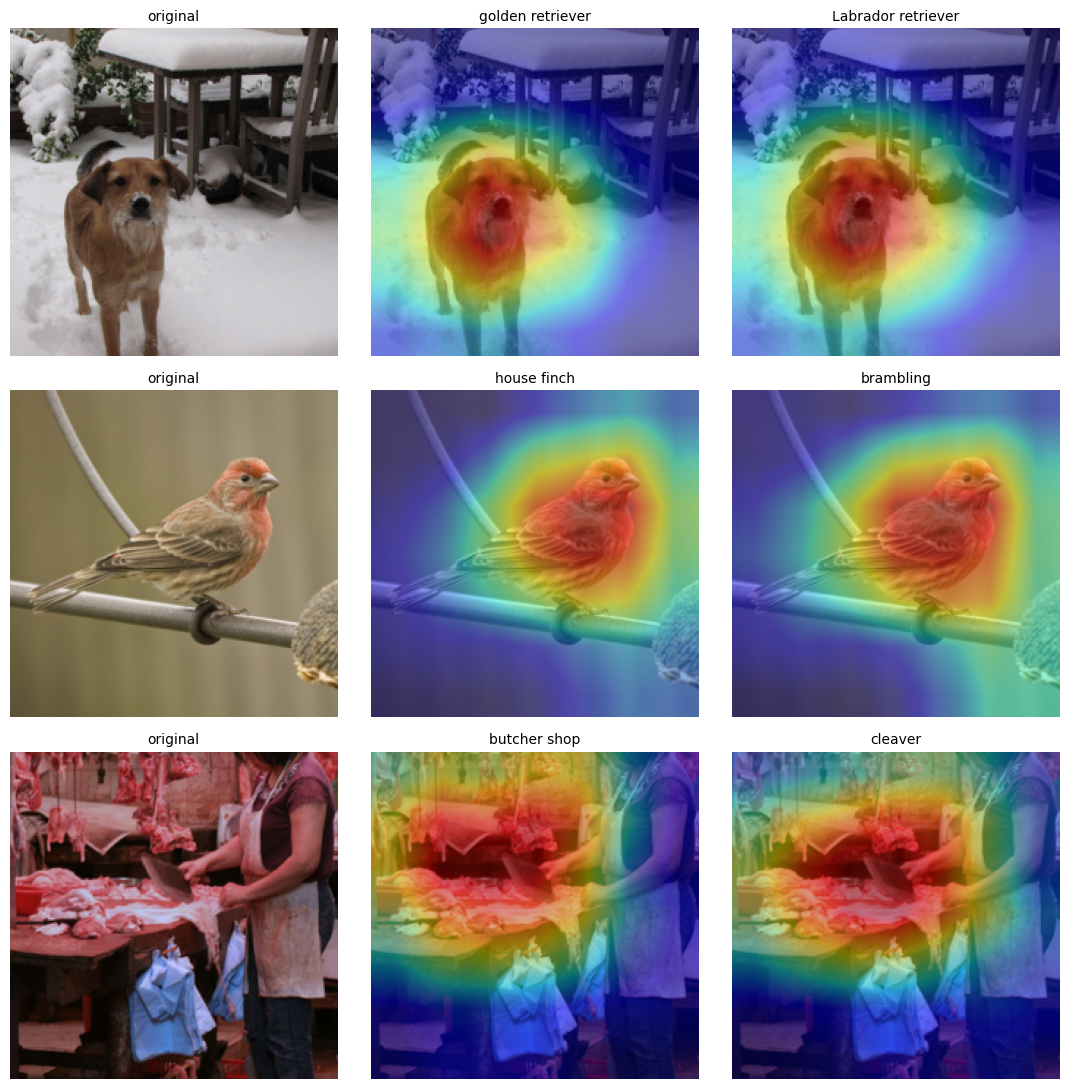

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for r, (name, img) in enumerate(zip(my_files, my_images)):
    probs = predict_probs(img)
    top2 = probs.topk(2).indices.tolist()

    x = preprocess(img).unsqueeze(0).to(device)
    axes[r, 0].imshow(to_numpy_img(x[0])); axes[r, 0].axis("off")
    axes[r, 0].set_title("original", fontsize=10)   # 그래프 안 텍스트는 영문 (Colab 한글 폰트 미지원)

    # TODO: top-1 클래스의 히트맵을 axes[r, 1]에,
    #       top-2 클래스의 히트맵을 axes[r, 2]에 그리세요 (show_gradcam 활용)
    show_gradcam(img, class_idx=top2[0], ax=axes[r, 1])
    show_gradcam(img, class_idx=top2[1], ax=axes[r, 2])
    # (빈칸 F) top-2 히트맵을 그릴 때 class_idx 인자에 무엇을 넣어야 하나요? → top2[1]을 넣어야 하며, 두 번째로 예측확률이 높은 클래스에 대한 설명을 구하는 과정이다.

plt.tight_layout(); plt.show()


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 1.3 답안 (여기에 작성)</b><br>· top-1 vs top-2 히트맵 비교에서 발견한 것:<br>
위의 세 이미지 모두 top-1과 top-2 히트맵이 비슷하게 나왔는데, 개와 새 이미지의 경우 얼굴과 몸통을 중심으로 강조되었고, 마지막 정육점 이미지의 경우 top-1은 고기와 그 주변을 넓게 강조한 반면, top-2는 칼과 고기 주변만 상대적으로 집중하는 차이를 보인다.
<br>· 그 차이/유사가 생긴 이유(모델 구조·클래스 관계 관점):<br>
top-1과 top-2 클래스가 시각적으로 유사하거나 서로 관련된 특징을 공유하기 때문인 것으로 생각했다. 특히 Golden retriever와 Labrador retriever, House finch와 Brambling은 외형이 유사하기 때문에 모델이 공통적인 특징을 활용했을 가능성이 있다. 반면 세 번째 이미지에서 정육점과 식칼은 서로 다른 개념이므로 각 클래스의 예측에 기여하는 영역에 차이가 발생한 것으로 보인다.
<br>· 배경 등 엉뚱한 곳을 보는 경우가 있었다면 그 의미:
새번째 이미지를 보면, 고기뿐만 아니라 작업대와 주변 환경도 활성화되었으며, 이는 모델이 객체 자체의 특징뿐 아니라 주변 배경 정보도 예측에 활용할 가능성을 보여준다. 따라서 배경에 대한 의존성이 높다면 배경이 달라졌을 때 예측 성능이 저하될 수 있다.
</div>

## 1.4 LIME — 같은 이미지를 Perturbation으로 설명하면?

이번에는 **모델 내부를 전혀 모른 채** superpixel을 켜고 끄는 LIME으로 같은 이미지를 설명합니다.

**해야 할 일**
1. 아래 코드로 첫 번째 배정 이미지의 LIME 설명을 만든다 *(1~2분 걸립니다 — 수업에서 왜 느리다고 했는지 떠올려 보세요!)*
2. `num_features`를 **3 → 10**으로 바꿔 다시 실행하고 두 결과를 비교한다
3. **같은 조건으로 한 번 더** 실행해 결과가 달라지는지(불안정성) 관찰한다

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💡 파라미터 읽는 법</b><br><code>num_samples</code> = 만들 변형 샘플 수(= 모델에 질의하는 횟수), <code>num_features</code> = 설명에 남길 superpixel 조각 수 (수업 목적함수의 Ω(g) — 복잡도 제한에 해당)</div>

In [13]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

def batch_predict(images):
    """LIME이 부르는 예측 함수: numpy 이미지 배치 → 클래스 확률 배치"""
    batch = torch.stack([preprocess(Image.fromarray(im)) for im in images]).to(device)
    with torch.no_grad():
        logits = model(batch)
    return F.softmax(logits, dim=1).cpu().numpy()

target_img = np.array(my_images[0].resize((224, 224)))
explainer = lime_image.LimeImageExplainer(random_state=SEED)

explanation = explainer.explain_instance(
    target_img,
    batch_predict,        # LIME은 이 함수를 '질의'만 함 — model-agnostic의 실체!
    top_labels=1,
    num_samples=1000,     # 변형 샘플 1000개 = 추론 1000번
)
print("LIME 설명 생성 완료 — top 클래스:", categories[explanation.top_labels[0]])


  0%|          | 0/1000 [00:00<?, ?it/s]

LIME 설명 생성 완료 — top 클래스: Labrador retriever


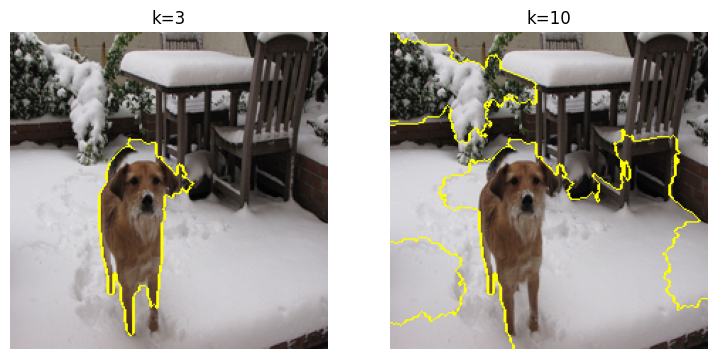

In [15]:
# num_features 를 3, 10 으로 바꿔 두 번 그려 비교하세요
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, k in zip(axes, [3, 10]):
    # TODO: explanation.get_image_and_mask(...)를 호출해
    #       positive_only=True, num_features=k, hide_rest=False 로 마스크를 얻고
    #       mark_boundaries(temp/255.0, mask) 를 ax.imshow 로 그리세요
    temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=True,
                                                 num_features=k, hide_rest=False)
    ax.imshow(mark_boundaries(temp / 255.0, mask)); ax.axis("off"); ax.set_title(f"k={k}")
    # (빈칸 G) num_features가 수업 목적함수의 어떤 항에 해당? → ____________
    pass
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

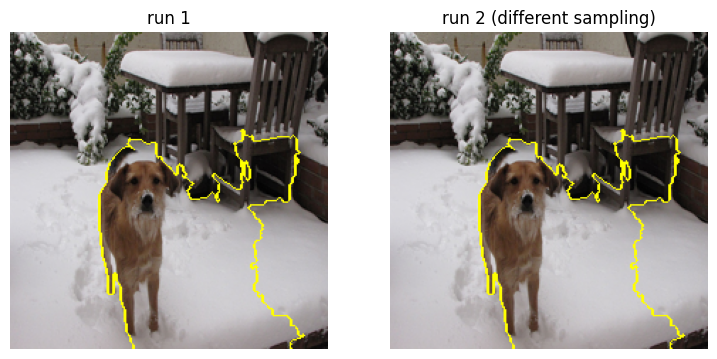

In [16]:
# 불안정성 실험: random_state를 바꿔 같은 설명을 한 번 더
explainer2 = lime_image.LimeImageExplainer(random_state=SEED + 1)
explanation2 = explainer2.explain_instance(target_img, batch_predict,
                                           top_labels=1, num_samples=1000)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (exp, t) in zip(axes, [(explanation, "run 1"), (explanation2, "run 2 (different sampling)")]):
    temp, mask = exp.get_image_and_mask(exp.top_labels[0], positive_only=True,
                                        num_features=5, hide_rest=False)
    ax.imshow(mark_boundaries(temp / 255.0, mask)); ax.axis("off"); ax.set_title(t)
plt.show()
# 두 실행의 결과가 완전히 같은가요? 다르다면 어느 정도 다른가요? → 아래 답안 셀에 기록


## 1.5 종합 비교 — Grad-CAM vs LIME (서술형)

1.3과 1.4의 결과를 옆에 놓고, 아래 표의 빈칸을 **본인의 실험 결과 근거**를 들어 채우세요.
"수업에서 배웠으니까"가 아니라 **"내 실험에서 이렇게 나왔으니까"**로 쓰는 것이 이 문제의 전부입니다.

| 비교 항목 | Grad-CAM (내 결과) | LIME (내 결과) |
|---|---|---|
| 걸린 시간 (체감) | 상대적으로 빠름 | 상대적으로 느림 |
| 설명의 형태·해상도 | 강아지 얼굴과 몸통을 중심으로 부드럽고 연속적인 히트맵 생성 | superpixel 경계를 따라 영역을 구분하며, k=3은 강아지 중심으로, k=10은 배경까지 포함 |
| 재실행 시 안정성 | 안정적 | 상대적으로 불안정 |
| 모델 내부 접근이 필요했나? | 필요. feature map과 gradient 사용 | 필요없음.  |

<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 1.5 답안 (여기에 작성)</b><br>· 위 표를 채운 뒤:<br>· 두 기법의 차이가 생기는 근본 원인 (Gradient vs Perturbation 축으로 설명):<br>
Grad-CAM은 선택한 클래스 점수를 중간 Feature Map에 대해 미분한 Gradient를 이용해 각 채널의 중요도를 계산하므로 위 실행에서도 강아지의 얼굴과 몸통을 중심으로 연속적인 히트맵이 나타난 것을 볼 수 있었다. 이와 달리 LIME은 이미지의 superpixel을 제거하거나 변경하면서 예측값이 어떻게 달라지는지 관찰하고, 이를 근사하는 모델로서 실제로 num_features=3일 때는 강아지 영역이 주로 선택되었으나 num_features=10에서는 주변 영역까지 함께 선택되었다.
<br>· 만약 ①모델 코드를 볼 수 없는 외부 API ②내가 학습시킨 CNN, 각각의 상황에서 어떤 기법을 쓸지와 이유:
- 외부 API: LIME은 모델 내부의 구조나 Gradient에 접근하지 않고도 입력을 변형했을 때의 예측값 변화를 이용해 설명을 생성할 수 있기 때문에 LIME을 선택할 것이다
- 직접 학습시킨 CNN: Grad-CAM을 우선 사용하여 모댈 내부 Feature map과 Gradient에 직접 접근할 수 있으며, 실제 실행 결과에서도 객체의 주요 부위를 중심으로 히트맵이 생성되어 모델의 판단에 기여한 영역을 직관적으로 확인할 수 있었다.
</div>

# 2. 심화 과제 (선택 — 둘 중 하나만 해도 됩니다)

## 2.1 SHAP — 표 데이터에서 Local ↔ Global 오가기

이미지에서 벗어나 SHAP이 가장 빛나는 **표 데이터 + 트리 모델** 조합을 경험합니다.
캘리포니아 주택 가격 데이터로 RandomForest를 학습하고 **TreeSHAP**으로 설명합니다.

**해야 할 일** — ① beeswarm(=summary) plot으로 **전역(Global)** 중요도를 읽고 ② waterfall plot으로 **개별 예측(Local)** 하나를 분해한 뒤
③ 수업에서 배운 **Local Accuracy**(기여도 합 = 예측값)를 코드로 직접 검증하세요.

R^2 (test): 0.768


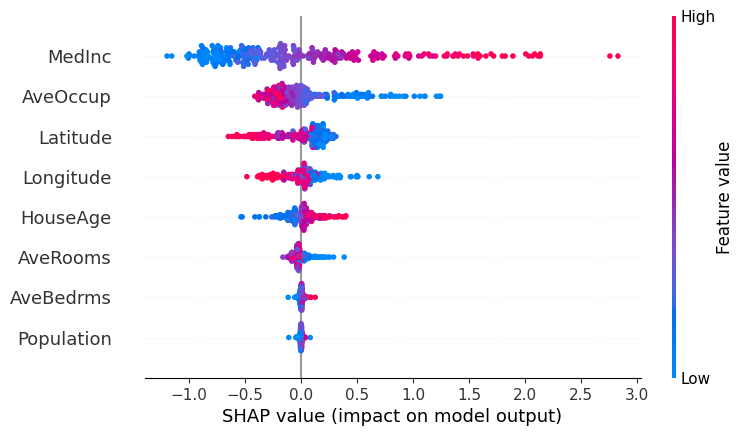

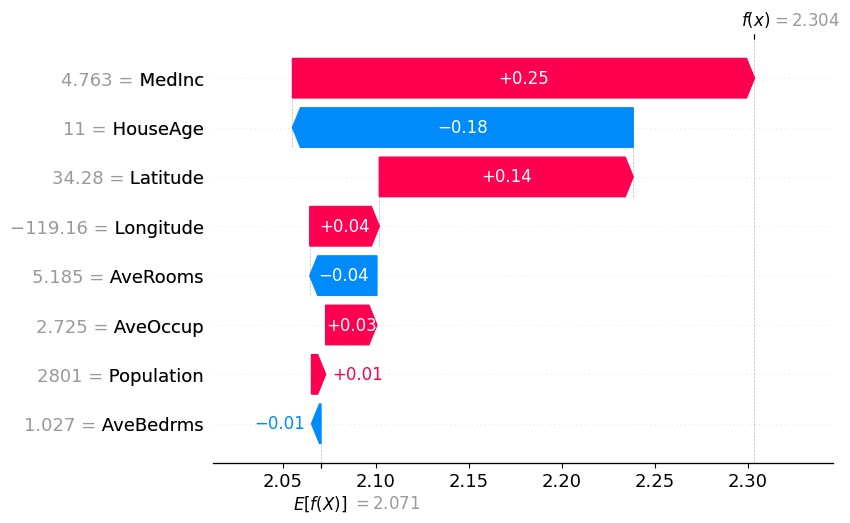

SHAP 합 + base_value: 2.303529961585561
모델 예측값: 2.3035299615855593
거의 같은가? True


In [17]:
import shap
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

rf = RandomForestRegressor(n_estimators=100, max_depth=8,
                           random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
print("R^2 (test):", round(rf.score(X_te, y_te), 3))

# TreeSHAP: 트리 구조를 이용해 정확한 Shapley 값을 빠르게 계산
explainer = shap.TreeExplainer(rf)
sv = explainer(X_te.iloc[:300])

shap.plots.beeswarm(sv)          # Global: 전체 경향
shap.plots.waterfall(sv[0])      # Local: 첫 번째 집 한 채의 분해

# TODO: Local Accuracy 검증 —
#   sv[0].values 의 합 + sv[0].base_values 가 rf.predict(첫 샘플) 과 (거의) 같은지 확인
# (빈칸 H) base_values는 수업 force plot 그림의 무엇에 해당? → base_values는 SHAP force plot에서 예측값의 출발점이 되는 기준값(모델의 기대 예측값)에 해당한다.
shap_sum = sv[0].values.sum() + sv[0].base_values
pred = rf.predict(X_te.iloc[[0]])[0]

print("SHAP 합 + base_value:", shap_sum)
print("모델 예측값:", pred)
print("거의 같은가?", np.isclose(shap_sum, pred))


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 2.1 답안 (여기에 작성)</b><br>· beeswarm에서 가장 중요한 feature 2개와, 그 값이 클 때 집값을 올리는지/내리는지:<br>

 - MedInc: 값이 클수록 양의 SHAP 값을 가지는 경향이 나타나므로 집값 예측을 높이는 방향으로 기여한다.

- AveOccup: 값이 클수록 음의 SHAP 값을 가지는 경향이 나타나므로 집값 예측을 낮추는 방향으로 기여한다.
<br>· waterfall의 첫 샘플: 예측을 가장 크게 움직인 feature와 방향:<br>
- 첫 번째 샘플에서 예측값에 가장 크게 기여한 특성은 MedInc(+0.25)로, 집값 예측을 높이는 방향으로 작용했다. 반면 HouseAge(-0.18)는 예측값을 가장 크게 낮추는 방향으로 기여했다
<br>· Local Accuracy 검증 결과:
- SHAP 값의 합과 기준값을 더한 결과는 2.303529961585561이고, 실제 Random Forest 모델의 예측값은 2.3035299615855593으로 거의 동일하게 나타났다. np.isclose() 결과도 True였으므로 SHAP의 Local Accuracy 성질이 성립함을 확인했다.
</div>

## 2.2 Sanity Check — 이 설명, 정말 모델을 보고 있나?

수업 3부에서 "설명 기법 자체도 검증 대상"이라고 했습니다 (Adebayo et al., 2018).
그 검증을 직접 해봅니다: **모델의 뒷부분 가중치를 랜덤으로 망가뜨렸을 때, Grad-CAM 히트맵이 함께 망가지는지** 확인합니다.

> 만약 모델을 망가뜨렸는데도 히트맵이 그대로라면 → 그 히트맵은 모델의 판단이 아니라
> 이미지의 윤곽선을 그리고 있었다는 뜻 (= 설명으로서 실격!)

In [ ]:
# 모델 복사 후 layer4와 fc의 가중치를 랜덤화
model_broken = copy.deepcopy(model)
for module in [model_broken.layer4, model_broken.fc]:
    for p in module.parameters():
        torch.nn.init.normal_(p, std=0.02)
model_broken.eval()

gradcam_broken = GradCAM(model_broken, model_broken.layer4[-1])

# TODO: 첫 번째 배정 이미지에 대해
#   ① 정상 모델의 히트맵 ② 망가진 모델의 히트맵 을 나란히 그리고 비교하세요
# (빈칸 I) 이 실험에서 히트맵이 '달라져야' 좋은 설명 기법인 이유 → ____________


# 3. 생성형 AI 활용 기록 (⚠️ 필수 제출)

<div style="background:#FEF2F2;border-left:6px solid #B91C1C;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B91C1C">반드시 작성해 주세요</b><br>이 셀이 비어 있으면 감점입니다. AI를 안 썼다면 '사용하지 않음'이라고 쓰면 됩니다. 솔직한 기록은 감점 사유가 아니며, 오히려 어떻게 도구를 썼는지가 평가 대상입니다.</div>

**작성 양식:**

### ① 핵심 대화 내역 붙여넣기
```
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).to(device).eval()   # (빈칸 A) .eval()을 호출하는 이유는? → ____________
categories = weights.meta["categories"]               # ImageNet 1000개 클래스 이름
preprocess = weights.transforms()                     # (빈칸 B) 이 전처리가 하는 일 두 가지는? → ____________

def predict_probs(img_pil):
    """PIL 이미지 → 1000개 클래스 확률 (torch.Tensor, shape [1000])"""
    x = preprocess(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():                             # (빈칸 C) 여기서 no_grad를 쓰는 이유는? → ____________
        logits = model(x)
    return F.softmax(logits, dim=1)[0].cpu()

for name, img in zip(my_files, my_images):
    probs = predict_probs(img)
    top5 = probs.topk(5)
    print(f"\n📷 {name}")
    for p, idx in zip(top5.values, top5.indices):
        print(f"   {categories[idx]:30s} {p*100:5.1f}%")
여기서 a랑 b에 대한 답변이 .eval을 하는 이유는 resnet18의 가중치로 평가하는 거고 b에서 transforms()는 정확히 어떤 의미인거야?

A는 이해한 방향이 거의 맞는데, 정확히는 ResNet18의 가중치로 평가하기 위해서가 아니라, 모델을 평가 모드(Evaluation Mode)로 전환하기 위해서 .eval()을 호출하는 거야.
① 빈칸 A — .eval()을 호출하는 이유
model = resnet18(weights=weights).to(device).eval()



각 부분을 나눠 보면 다음과 같아.
- resnet18(weights=weights): ImageNet으로 사전학습된 가중치를 불러옴
- .to(device): 모델을 CPU 또는 GPU로 이동
- .eval(): 모델을 평가 모드로 전환
특히 .eval()은 Batch Normalization과 Dropout 등의 동작을 추론에 적합하게 변경해.

ResNet18에서는 Batch Normalization이 중요한데, 학습 모드에서는 현재 배치의 평균과 분산을 사용하고 평가 모드에서는 학습 중 저장된 이동 평균과 분산을 사용해.

제출용 답안 A:
모델을 평가 모드로 전환하여 Batch Normalization 등이 학습 시와 다르게 동작하도록 하고, 안정적인 추론 결과를 얻기 위해서이다.

② 빈칸 B — weights.transforms()의 의미
weights = ResNet18_Weights.IMAGENET1K_V1preprocess = weights.transforms()



여기서 transforms()는 해당 사전학습 가중치에 맞는 이미지 전처리 과정을 불러오는 함수야.

ResNet18은 아무 형태의 이미지나 그대로 입력받는 게 아니라, 학습할 때 사용한 입력 형식에 맞춰 이미지를 변환해야 해.

fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for r, (name, img) in enumerate(zip(my_files, my_images)):
    probs = predict_probs(img)
    top2 = probs.topk(2).indices.tolist()

    x = preprocess(img).unsqueeze(0).to(device)
    axes[r, 0].imshow(to_numpy_img(x[0])); axes[r, 0].axis("off")
    axes[r, 0].set_title("original", fontsize=10)   # 그래프 안 텍스트는 영문 (Colab 한글 폰트 미지원)

    # TODO: top-1 클래스의 히트맵을 axes[r, 1]에,
    #       top-2 클래스의 히트맵을 axes[r, 2]에 그리세요 (show_gradcam 활용)
    show_gradcam(img, class_idx=top2[0], ax=axes[r, 1])
    show_gradcam(img, class_idx=top2[1], ax=axes[r, 2])
    # (빈칸 F) top-2 히트맵을 그릴 때 class_idx 인자에 무엇을 넣어야 하나요? → ____________

plt.tight_layout(); plt.show()
 여기서 히트맵을 그릴 때 top-1과 top-2 히트맵이 각각 무슨 차이가 있어?

 Top-1과 Top-2 히트맵의 차이는 모델이 같은 이미지를 서로 다른 클래스로 판단할 때, 각각 어떤 영역을 근거로 사용하는지에 있어.
1. Top-1과 Top-2의 의미
예를 들어 고양이 사진을 ResNet18에 입력했을 때 다음과 같은 예측 결과가 나왔다고 해보자.
순위	예측 클래스	확률
Top-1	Persian cat	65%
Top-2	Angora cat	25%

이때 두 히트맵은 다음과 같은 차이가 있어.









Top-1 Grad-CAM

모델이 Persian cat이라고 판단하는 데 긍정적으로 기여한 영역을 강조










Top-2 Grad-CAM

모델이 Angora cat이라고 판단하는 데 긍정적으로 기여한 영역을 강조


위 사진은 클래스의 예시이고, 실제 Grad-CAM에서는 동일한 입력 이미지 위에 서로 다른 히트맵을 표시해.
2. 코드에서는 어떻게 달라질까?
show_gradcam(img, class_idx=top2[0], ax=axes[r, 1])show_gradcam(img, class_idx=top2[1], ax=axes[r, 2])



Grad-CAM 내부에서 선택한 클래스의 점수를 이용해 역전파하지?
score = logits[0, class_idx]score.backward()



여기서 class_idx가 달라지면 미분하는 클래스 점수도 달라져.
\[
\text{Top-1:}\quad \frac{\partial y^{c_1}}{\partial A^k}
\]

\[
\text{Top-2:}\quad \frac{\partial y^{c_2}}{\partial A^k}
\]

따라서 채널별 중요도 \(\alpha_k^c\)가 달라지고, 최종적으로 생성되는 히트맵도 달라질 수 있어.
3. 실제 히트맵을 비교할 때
- 두 히트맵이 비슷하다면: 모델이 두 클래스를 판단할 때 유사한 시각적 특징을 활용할 가능성이 있어.
- 두 히트맵이 다르다면: 각 클래스의 판단에 서로 다른 이미지 영역이 기여하고 있을 가능성이 있어.
다만 히트맵이 비슷하다고 해서 모델이 두 클래스를 동일하게 판단한다는 의미는 아니야. Grad-CAM은 클래스별 기여 영역을 대략적으로 시각화하는 방법이기 때문이야.
```

### ② AI 답변을 그대로 쓰지 않고 직접 판단/수정한 부분
- Grad-CAM 구현 과정에서 AI가 제안한 코드에 keepdim=True를 사용했는데, 이후 F.interpolate()에서 텐서 차원 불일치 오류가 발생했다. 오류 메시지와 텐서의 shape을 확인한 뒤, 채널 합산 과정에서 keepdim=True를 제거하여 정상적으로 히트맵이 생성되도록 수정했다.


# 4. 회고

한 학기 뒤의 나에게 남기는 메모라고 생각하고 가볍게 적어 주세요.

- **가장 신기했던 결과** 하나: Grad-CAM에서 Top-1과 Top-2 클래스의 히트맵이 예상보다 비슷하게 나타난 것이 신기했다. 서로 다른 클래스에 대한 설명인데도 유사한 영역을 강조하는 것을 보고, 모델이 관련된 클래스들을 구분할 때 공통적인 시각적 특징을 활용할 수 있다는 점이 흥미로웠다.
- 수업 내용 중 과제를 하며 **비로소 이해된 것**: Grad-CAM과 LIME의 차이를 실제 결과를 비교하면서 더 명확하게 이해할 수 있었다. Grad-CAM은 Gradient를 이용해 클래스별 중요 영역을 시각화하는 반면, LIME은 입력 영역을 변경했을 때 예측이 어떻게 달라지는지를 이용한다는 점이 이해되었다. 특히 LIME에서 num_features를 늘렸을 때 강아지뿐 아니라 배경 영역까지 선택되는 것을 보며 설명에 포함되는 영역의 수가 해석에 영향을 준다는 점을 확인할 수 있었다.

---
<div style="text-align:center;opacity:.75">수고했습니다! 🎉 — 모든 셀의 실행 결과가 남아 있는지 확인한 뒤 .ipynb로 제출해 주세요</div>